In [1]:
# Instala e importa o gdown para baixar a pasta do Drive do curso
!pip install -q gdown
import gdown

# Link da pasta oficial do projeto no Google Drive
url_pasta = 'https://drive.google.com/drive/folders/1_QcYvhSoJO6SxOJz8Om6gaVuWyPZKdMs'
gdown.download_folder(url_pasta, quiet=True, use_cookies=False)

['/content/ProjetoModulo-1/anotações do Departamento de Engenharia',
 '/content/ProjetoModulo-1/manutencao_preditiva.csv']

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# modelagem e pré-porcessamento
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

#Balanceamento de dados
from imblearn.over_sampling import SMOTE


In [3]:
import os

# Carregamento da base de dados com caminho flexível
caminho = 'manutencao_preditiva.csv' if os.path.exists('manutencao_preditiva.csv') else 'ProjetoModulo-1/manutencao_preditiva.csv'
df = pd.read_csv(caminho)

# Visualizando as primeiras linhas
df.head()

,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0


In [4]:
# Dimensões (linhas x colunas)
print(f"Linhas e Colunas: {df.shape}")

# Tipos de dados e contagem de não-nulos
df.info()

# Resumo estatístico das variáveis numéricas
df.describe()

Linhas e Colunas: (10000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   udi                      10000 non-null  int64  
 1   id_produto               10000 non-null  object 
 2   tipo                     10000 non-null  object 
 3   temperatura_ar_k         9500 non-null   float64
 4   temperatura_processo_k   9500 non-null   float64
 5   velocidade_rotacao_rpm   9500 non-null   float64
 6   torque_nm                9500 non-null   float64
 7   desgaste_ferramenta_min  10000 non-null  int64  
 8   falha_maquina            10000 non-null  int64  
 9   falha_twf                10000 non-null  int64  
 10  falha_hdf                10000 non-null  int64  
 11  falha_pwf                10000 non-null  int64  
 12  falha_osf                10000 non-null  int64  
 13  falha_rnf                10000 non-null  int64 

,udi,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
count,10000.00000,9500.000000,9500.000000,9500.000000,9500.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.002158,310.000895,1539.245263,39.974168,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.001689,1.486432,180.273589,9.995453,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.100000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1504.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1613.000000,46.700000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


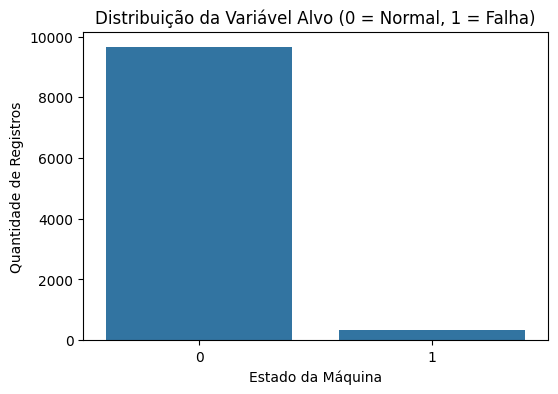

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(x='falha_maquina', data=df)
plt.title('Distribuição da Variável Alvo (0 = Normal, 1 = Falha)')
plt.xlabel('Estado da Máquina')
plt.ylabel('Quantidade de Registros')
plt.show()

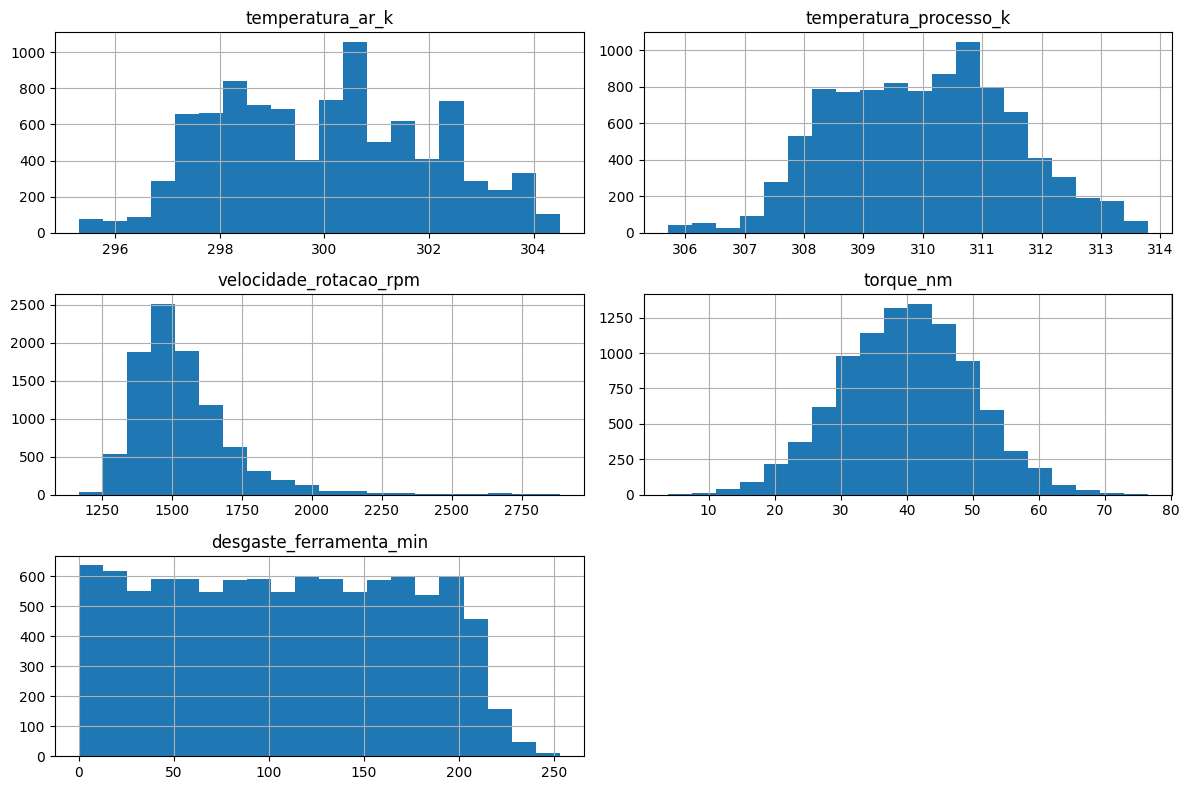

In [6]:
# Histograma das variáveis operacionais contínuas
colunas_sensores = ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min']
df[colunas_sensores].hist(bins=20, figsize=(12, 8))
plt.tight_layout()
plt.show()

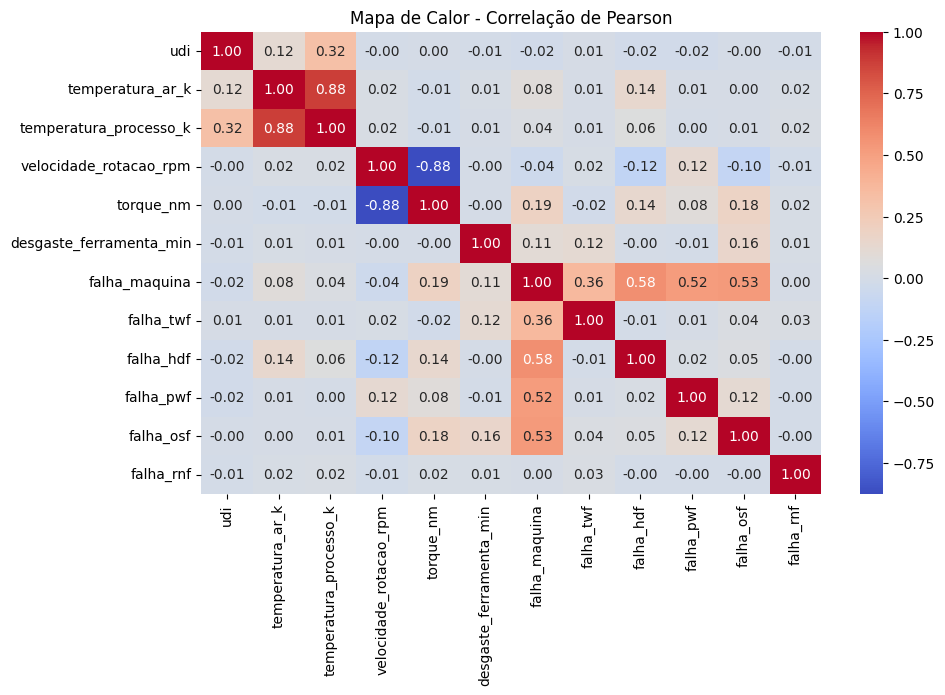

In [7]:
plt.figure(figsize=(10, 6))
# Calculando a correlação apenas das colunas numéricas
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Mapa de Calor - Correlação de Pearson')
plt.show()

### Análise dos Gráficos (EDA)
Desbalanceamento (Gráfico 1): A quase totalidade dos registros é de operação normal (classe 0) e as falhas (classe 1) são muito raras. Por isso, precisamos usar divisão estratificada e balancear o treino com SMOTE.

Sensores (Gráfico 2): Os sensores funcionam em escalas muito diferentes e a rotação apresenta outliers. Isso justifica padronizar as medidas antes de rodar o KNN.

Correlações (Gráfico 3): Existe uma forte relação inversa entre rotação e torque (-0,88). As colunas de falhas específicas não serão usadas no treino para evitar que o modelo "espione" as respostas (vazamento de dados).

Total de linhas duplicadas encontradas: 0

Contagem de valores ausentes por coluna:
udi                          0
id_produto                   0
tipo                         0
temperatura_ar_k           500
temperatura_processo_k     500
velocidade_rotacao_rpm     500
torque_nm                  500
desgaste_ferramenta_min      0
falha_maquina                0
falha_twf                    0
falha_hdf                    0
falha_pwf                    0
falha_osf                    0
falha_rnf                    0
dtype: int64


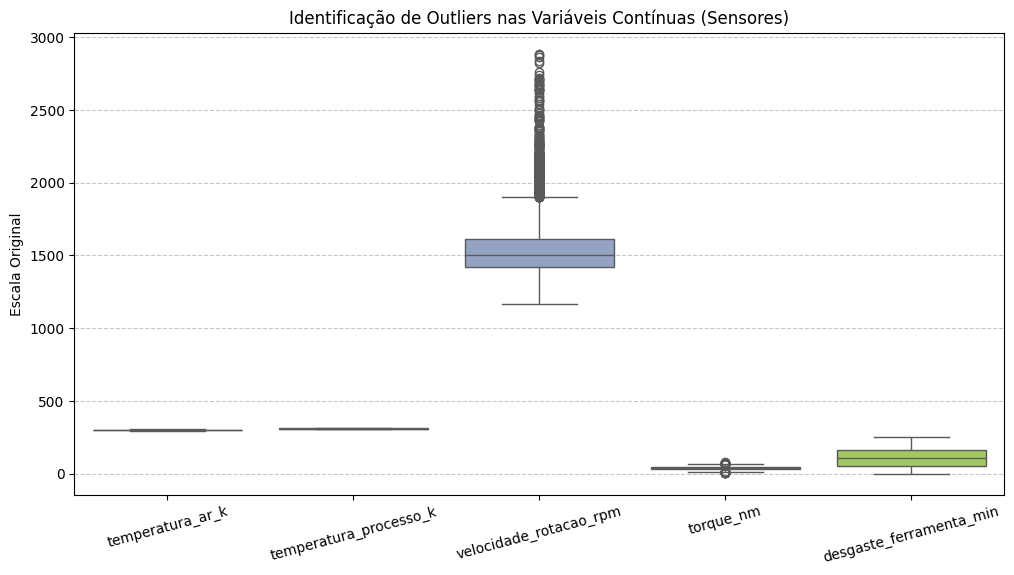

In [8]:
# --- FASE 2: LIMPEZA E TRATAMENTO DE DADOS (DATA PREP) ---

# 1. Identificação e remoção de registros duplicados
qtd_duplicados = df.duplicated().sum()
print(f"Total de linhas duplicadas encontradas: {qtd_duplicados}")

if qtd_duplicados > 0:
    df = df.drop_duplicates()
    print("Linhas duplicadas removidas com sucesso.")

# 2. Verificação de dados ausentes (nulos)
print("\nContagem de valores ausentes por coluna:")
print(df.isnull().sum())

# 3. Boxplot para identificação visual de outliers nas variáveis operacionais
sensores = ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min']

plt.figure(figsize=(12, 6))
sns.boxplot(data=df[sensores], palette='Set2')
plt.title('Identificação de Outliers nas Variáveis Contínuas (Sensores)')
plt.ylabel('Escala Original')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [9]:
# Imputação dos valores ausentes pela MEDIANA
colunas_nulas = ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm']

for col in colunas_nulas:
    mediana = df[col].median()
    df[col] = df[col].fillna(mediana)

# Confirmação da eliminação dos nulos
print("Valores ausentes restantes:")
print(df[colunas_nulas].isnull().sum())

Valores ausentes restantes:
temperatura_ar_k          0
temperatura_processo_k    0
velocidade_rotacao_rpm    0
torque_nm                 0
dtype: int64


### Justificativa do uso da Mediana (Fase 2)
Escolhemos preencher os dados vazios com a mediana em vez da média porque variáveis operacionais como rotação e torque apresentam outliers e distribuições assimétricas. A média seria distorcida por esses valores extremos, enquanto a mediana preserva o valor típico real dos sensores.

In [10]:
# --- FASE 3: FEATURE ENGINEERING ---
# Criação da feature de potência mecânica (Rotação x Torque)
df['potencia'] = df['velocidade_rotacao_rpm'] * df['torque_nm']

# Visualizando as primeiras linhas com a nova variável
df[['velocidade_rotacao_rpm', 'torque_nm', 'potencia']].head()

,velocidade_rotacao_rpm,torque_nm,potencia
0,1551.0,42.8,66382.8
1,1408.0,46.3,65190.4
2,1498.0,49.4,74001.2
3,1504.0,40.1,60310.4
4,1408.0,40.0,56320.0


In [11]:
# --- FASE 4: DIVISÃO E BALANCEAMENTO ---

# 1. Definição das variáveis preditoras (X) e do alvo (y)
colunas_para_remover = [
    'udi', 'id_produto', 'tipo', 'falha_maquina',
    'falha_twf', 'falha_hdf', 'falha_pwf', 'falha_osf', 'falha_rnf'
]

X = df.drop(columns=colunas_para_remover)
y = df['falha_maquina']

# 2. Divisão Treino (80%) e Teste (20%) com estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Dimensões originais de treino: {X_train.shape}")
print(f"Distribuição original do alvo no treino:\n{y_train.value_counts()}")

# 3. Balanceamento com SMOTE aplicado EXCLUSIVAMENTE nos dados de treino
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"\nDimensões após SMOTE no treino: {X_train_res.shape}")
print(f"Distribuição do alvo no treino após SMOTE:\n{y_train_res.value_counts()}")

Dimensões originais de treino: (8000, 6)
Distribuição original do alvo no treino:
falha_maquina
0    7729
1     271
Name: count, dtype: int64

Dimensões após SMOTE no treino: (15458, 6)
Distribuição do alvo no treino após SMOTE:
falha_maquina
0    7729
1    7729
Name: count, dtype: int64


In [12]:
# --- FASE 5: ESCALONAMENTO DE VARIÁVEIS (StandardScaler) ---
from sklearn.preprocessing import StandardScaler

# Instanciando o padronizador
scaler = StandardScaler()

# Ajustando e transformando o treino balanceado; apenas transformando o teste (evita vazamento)
X_train_knn = scaler.fit_transform(X_train_res)
X_test_knn = scaler.transform(X_test)

# Nota: Para a Árvore de Decisão, utilizamos diretamente os dados sem escala:
# Treino: X_train_res | Teste: X_test
print("Escalonamento concluído para o KNN!")
print(f"Formato dos dados escalonados: Treino {X_train_knn.shape} | Teste {X_test_knn.shape}")

Escalonamento concluído para o KNN!
Formato dos dados escalonados: Treino (15458, 6) | Teste (2000, 6)


### No KNN: O modelo KNN funciona calculando a distância entre os pontos. Se não deixarmos tudo na mesma escala, colunas com números muito grandes (como rotação e potência) vão ter mais peso do que as outras e distorcer o resultado. Usamos o fit apenas no treino para o modelo não "espiar" os dados de teste (data leakage).
Na Árvore de Decisão: A árvore não precisa de escalonamento porque ela só faz perguntas simples de "maior ou menor" para dividir os dados. Como ela não calcula distância, a escala dos números não faz diferença no resultado final.
.

In [13]:
# --- FASE 6: AJUSTE DE HIPERPARÂMETROS E OVERFITTING ---

print("=== TESTE DO KNN (variando K) ===")
# Testando 3 valores ímpares de vizinhos
for k in [3, 5, 7]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_knn, y_train_res)

    acc_treino = accuracy_score(y_train_res, knn.predict(X_train_knn))
    acc_teste = accuracy_score(y_test, knn.predict(X_test_knn))
    print(f"K = {k} -> Treino: {acc_treino:.4f} | Teste: {acc_teste:.4f}")

print("\n=== TESTE DA ÁRVORE DE DECISÃO (variando max_depth) ===")
# Testando 3 profundidades (rasa, média e sem limite)
for prof in [3, 5, None]:
    arvore = DecisionTreeClassifier(max_depth=prof, random_state=42)
    arvore.fit(X_train_res, y_train_res)

    acc_treino = accuracy_score(y_train_res, arvore.predict(X_train_res))
    acc_teste = accuracy_score(y_test, arvore.predict(X_test))
    print(f"Profundidade = {prof} -> Treino: {acc_treino:.4f} | Teste: {acc_teste:.4f}")

=== TESTE DO KNN (variando K) ===
K = 3 -> Treino: 0.9583 | Teste: 0.9065
K = 5 -> Treino: 0.9505 | Teste: 0.8960
K = 7 -> Treino: 0.9429 | Teste: 0.8890

=== TESTE DA ÁRVORE DE DECISÃO (variando max_depth) ===
Profundidade = 3 -> Treino: 0.8504 | Teste: 0.8925
Profundidade = 5 -> Treino: 0.8984 | Teste: 0.9065
Profundidade = None -> Treino: 0.9896 | Teste: 0.9385


### Análise de Overfitting (Fase 6)
* **KNN:** O melhor resultado no teste foi com K = 3 (90,65%), mas no treino ele atingiu 95,83% (uma diferença de ~5,2 pontos percentuais). Com K = 5 e K = 7, a distância entre treino e teste diminuiu, trazendo maior estabilidade.
* **Árvore de Decisão:** O sobreajuste evidente (overfitting) ocorreu com profundidade livre (None), onde a árvore praticamente decorou o treino (98,96%), embora tenha mantido 93,85% no teste. A configuração com max_depth = 5 garantiu maior equilíbrio e capacidade de generalização (89,84% no treino e 90,65% no teste).

In [14]:
# --- FASE 7: AVALIAÇÃO DA ACURÁCIA E VEREDITO FINAL ---

# 1. Treinando e avaliando o melhor KNN (K = 3) na base de teste
melhor_knn = KNeighborsClassifier(n_neighbors=3)
melhor_knn.fit(X_train_knn, y_train_res)
melhor_acc_knn = accuracy_score(y_test, melhor_knn.predict(X_test_knn))

# 2. Treinando e avaliando a melhor Árvore de Decisão na base de teste
melhor_arvore = DecisionTreeClassifier(max_depth=None, random_state=42)
melhor_arvore.fit(X_train_res, y_train_res)
melhor_acc_arvore = accuracy_score(y_test, melhor_arvore.predict(X_test))

# 3. Exibição dos resultados finais calculados
print("=== RESULTADO FINAL NO CONJUNTO DE TESTE ===")
print(f"Melhor KNN (K=3): {melhor_acc_knn * 100:.2f}% de acurácia")
print(f"Melhor Árvore de Decisão: {melhor_acc_arvore * 100:.2f}% de acurácia")

=== RESULTADO FINAL NO CONJUNTO DE TESTE ===
Melhor KNN (K=3): 90.65% de acurácia
Melhor Árvore de Decisão: 93.85% de acurácia


### Conclusão e Veredito Final (Fase 7)
Comparando os dois modelos na base de teste, a Árvore de Decisão obteve o melhor desempenho final, atingindo 93,85% de acurácia contra 90,65% do KNN
.
Além da maior taxa de acerto
, a Árvore de Decisão é mais rápida para executar e mais fácil de explicar na indústria, já que funciona por regras claras de decisão
. Por isso, a Árvore de Decisão é o modelo recomendado para ser colocado na linha de produção da fábrica
.